# 10. Baseline Inference: Qwen2.5-3B-Instruct (4-Bit)

Notebook ini khusus digunakan untuk melakukan inferensi model baseline **Qwen2.5-3B-Instruct** yang di-quantize ke 4-bit menggunakan framework **Unsloth** (`FastLanguageModel`).

Inferensi dilakukan sebanyak 2 kali pada 2 skenario berbeda:
1. **Zero-Shot**: Menggunakan prompt instruksi tanpa contoh.
2. **Few-Shot**: Menggunakan prompt instruksi dengan menyertakan contoh (few-shot examples).

**Tugas yang dievaluasi:**
- **Task A (GABSA)**: Aspect, Sentiment, and Evidence extraction dari ulasan rumah sakit.
- **Task B (Management Summary)**: Pembuatan ringkasan analitik strategis berdasarkan statistik agregat ulasan.

Mekanisme inferensi model 4-bit Unsloth di notebook ini mengadopsi cara yang sama seperti di notebook `08_multitask_finetuning_gabsa_summary_v3(1).ipynb`, sementara skenario evaluasi (zero-shot, few-shot, metric parsing, comparison, & visualization) mengacu pada notebook `eval_complete_models_comparison.ipynb`.


## 0. Install Dependencies
Instalasi library yang dibutuhkan seperti `unsloth`, `bitsandbytes`, `trl`, `rouge-score`, dan `bert-score`.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Install Unsloth & dependencies
!pip install trl bitsandbytes unsloth
!pip install bert-score rouge-score


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 kB 3.3 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of unsloth to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 5.6 MB/s eta 0:00:00
INFO: pip is still looking at multiple versions of unsloth to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 6.1 MB/

## 1. Imports & Environment Setup


In [ ]:
import os
import json
import re
import time
import random
import difflib
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from dataclasses import dataclass, field, asdict
from typing import List, Dict, Optional
from datasets import Dataset
from unsloth import FastLanguageModel
from unsloth.chat_templates import get_chat_template
from sklearn.metrics import classification_report, roc_auc_score
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn

# Pastikan grafik matplotlib ditampilkan secara inline
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


🦥 Unsloth Zoo will now patch everything to make training faster!


Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Using device: cuda


## 2. Paths Configuration
Tentukan letak file dataset test set `gabsa_test.jsonl` dan `summary_test.xlsx`. Anda bisa menyesuaikan flag `IS_COLAB` untuk menjalankan notebook ini di Google Colab atau di local server.


In [ ]:
# Konfigurasi path (Colab vs Local)
IS_COLAB = True  # Ubah ke False jika dijalankan secara lokal

if IS_COLAB:
    # Path di Google Drive
    GABSA_TEST_PATH = "/content/drive/MyDrive/Skripsi_v2/data/splits/gabsa_test.jsonl"
    SUMMARY_TEST_PATH = "/content/drive/MyDrive/Skripsi_v2/data/splits/summary_test.xlsx"
    OUTPUT_DIR = "/content/drive/MyDrive/Skripsi_v2/evaluation_results/baseline/"
    CACHE_DIR = "/content/drive/MyDrive/Skripsi_v2/predictions/baseline/"
else:
    # Path relatif lokal
    GABSA_TEST_PATH = "../../eda_evaluation/new_data/gabsa_test.jsonl"
    SUMMARY_TEST_PATH = "../../eda_evaluation/new_data/summary_test.xlsx"
    OUTPUT_DIR = "./evaluation_results/"
    CACHE_DIR = "../../eda_evaluation/new_data/"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

print(f"GABSA test path: {GABSA_TEST_PATH}")
print(f"Summary test path: {SUMMARY_TEST_PATH}")
print(f"Output folder: {OUTPUT_DIR}")
print(f"Cache folder: {CACHE_DIR}")


GABSA test path: /content/drive/MyDrive/Skripsi_v2/data/splits/gabsa_test.jsonl
Summary test path: /content/drive/MyDrive/Skripsi_v2/data/splits/summary_test.xlsx
Output folder: /content/drive/MyDrive/Skripsi_v2/evaluation_results/baseline/
Cache folder: /content/drive/MyDrive/Skripsi_v2/predictions/baseline/


## 3. Data Loading Functions


In [ ]:
def load_gabsa_test(file_path):
    """Memuat data ulasan GABSA (Task A) dalam format JSONL."""
    records = []
    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))
    print(f"Loaded {len(records)} GABSA test records.")
    return records

def load_summary_test(file_path):
    """Memuat data summary (Task B) dari Excel."""
    df = pd.read_excel(file_path)
    required_cols = {"input_stats", "target_summary"}
    if not required_cols.issubset(df.columns):
        raise ValueError(f"Excel must contain: {required_cols}")

    records = []
    for idx, row in df.iterrows():
        records.append({
            "input_stats": str(row["input_stats"]).strip(),
            "target_summary": str(row["target_summary"]).strip()
        })
    print(f"Loaded {len(records)} Summary test records.")
    return records

# Load datasets
try:
    gabsa_test_data = load_gabsa_test(GABSA_TEST_PATH)
    summary_test_data = load_summary_test(SUMMARY_TEST_PATH)
except Exception as e:
    print(f"Error loading datasets: {e}")
    print("Pastikan path file sudah benar dan Google Drive sudah termount jika menggunakan Colab.")


Loaded 1181 GABSA test records.
Loaded 15 Summary test records.


## 4. Model & Tokenizer Configuration (Qwen2.5-3B via Unsloth)
Memuat model baseline `unsloth/Qwen2.5-3B-Instruct-bnb-4bit` dalam format 4-bit precision menggunakan Unsloth.


In [ ]:
MODEL_NAME   = "unsloth/Qwen2.5-3B-Instruct-bnb-4bit"
MAX_SEQ_LEN  = 1024
LOAD_IN_4BIT = True

# Load model baseline 4-bit
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LEN,
    dtype=None,
    load_in_4bit=LOAD_IN_4BIT,
)

# Konfigurasi chat template Qwen
tokenizer = get_chat_template(
    tokenizer,
    chat_template="qwen-2.5",
)

# Masuk ke mode inferensi
FastLanguageModel.for_inference(model)
print("Model baseline berhasil dimuat dan siap untuk inferensi.")


==((====))==  Unsloth 2025.11.1: Fast Qwen2 patching. Transformers: 4.57.2.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/2.05G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

Model baseline berhasil dimuat dan siap untuk inferensi.


## 5. Prompts & Few-Shot Templates
Definisi system prompt serta template/contoh few-shot untuk kedua task (GABSA dan Summarization).


In [ ]:
# System prompt baseline untuk Task A & B
BASE_GABSA_SYSTEM_PROMPT = (
    "Anda adalah pakar NLP kesehatan. Ekstrak aspek, sentimen, dan bukti teks dari ulasan rumah sakit "
    "ke dalam format JSON yang valid dengan skema: {\"labels\": [{\"aspect\": \"nama_aspek\", \"sentiment\": \"positif/negatif/netral\", \"evidence\": \"bukti_teks\"}]}. "
    "Aspek yang dituju terbatas pada: pelayanan, fasilitas, kebersihan, waktu_tunggu, administrasi, tenaga_medis, parkir_akses."
)

SUMMARY_SYSTEM_PROMPT = (
    "Anda adalah konsultan manajemen rumah sakit senior. "
    "Buatlah ringkasan analitik strategis dalam Bahasa Indonesia dengan struktur Ringkasan Eksekutif, Keunggulan (Strengths), Masalah Kritis (Pain Points), dan Rekomendasi Strategis. Berdasarkan statistik ulasan yang diberikan."
)

# Contoh Few-Shot untuk Task A (GABSA)
GABSA_FEW_SHOT_EXAMPLES = [
    {
        "role": "user",
        "content": "Pelayanan rumah sakit ini sangat baik, perawat ramah dan cekatan. Namun ruang tunggunya agak kotor."
    },
    {
        "role": "assistant",
        "content": '{"labels": [{"aspect": "pelayanan", "sentiment": "positif", "evidence": "Pelayanan rumah sakit ini sangat baik, perawat ramah dan cekatan"}, {"aspect": "tenaga_medis", "sentiment": "positif", "evidence": "perawat ramah dan cekatan"}, {"aspect": "kebersihan", "sentiment": "negatif", "evidence": "ruang tunggunya agak kotor"}, {"aspect": "fasilitas", "sentiment": "negatif", "evidence": "ruang tunggunya agak kotor"}]}'
    },
    {
        "role": "user",
        "content": "Dokter spesialisnya kurang ramah dan pembayarannya lama sekali, tapi parkirnya luas."
    },
    {
        "role": "assistant",
        "content": '{"labels": [{"aspect": "tenaga_medis", "sentiment": "negatif", "evidence": "Dokter spesialisnya kurang ramah"}, {"aspect": "waktu_tunggu", "sentiment": "negatif", "evidence": "pembayarannya lama sekali"}, {"aspect": "parkir_akses", "sentiment": "positif", "evidence": "parkirnya luas"}]}'
    }
]

# Contoh Few-Shot untuk Task B (Summary)
SUMMARY_FEW_SHOT_EXAMPLES = [
    {
        "role": "user",
        "content": '{"total_reviews": 2, "aspect_sentiment_distribution": {"pelayanan": {"positif": 2}}, "key_snippets": {"positive_highlights": ["pelayanan bagus dan ramah", "susternya baik sekali"]}}'
    },
    {
        "role": "assistant",
        "content": "Ringkasan Eksekutif: Rumah sakit menunjukkan performa pelayanan yang luar biasa baik dengan sentimen positif penuh dari pasien.\nKeunggulan: Pelayanan perawat dinilai sangat ramah, sigap, dan bersahabat oleh pasien.\nMasalah Kritis: Tidak ditemukan keluhan atau masalah kritis.\nRekomendasi Strategis: Pertahankan kualitas pelayanan prima yang diberikan oleh perawat agar kepuasan pasien tetap stabil."
    }
]


## 6. Parsing & Evaluation Helper Functions
Fungsi pembantu untuk mem-parsing output JSON model secara aman (strict & lenient) serta fungsi untuk menghitung metrik evaluasi GABSA (F1, Accuracy, ROC-AUC) dan Summary (ROUGE, BERTScore).


In [ ]:
def safe_parse_json(content):
    """Parsing JSON dengan toleransi format (strict dan lenient)."""
    if not isinstance(content, str) or not content.strip():
        return [], False, False

    # 1. Strict Parsing
    try:
        data = json.loads(content.strip())
        is_valid_strict = False
        labels = []
        if isinstance(data, dict):
            if "labels" in data:
                labels = data["labels"]
                is_valid_strict = isinstance(labels, list)
            elif "output" in data:
                labels = data["output"]
                is_valid_strict = isinstance(labels, list)
            elif "aspect" in data and "sentiment" in data and "evidence" in data:
                labels = [data]
                is_valid_strict = True
        elif isinstance(data, list):
            labels = data
            is_valid_strict = True

        if is_valid_strict:
            for item in labels:
                if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item or "evidence" not in item:
                    is_valid_strict = False
                    break
        if is_valid_strict:
            return labels, True, True
    except:
        pass

    # 2. Lenient Parsing (Regex Fallback)
    try:
        match = re.search(r'\{.*\}', content.strip(), re.DOTALL)
        if match:
            data = json.loads(match.group())
            labels = data.get("labels", data.get("output", []))
            if isinstance(labels, list):
                is_valid_lenient = True
                for item in labels:
                    if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item or "evidence" not in item:
                        is_valid_lenient = False
                        break
                if is_valid_lenient:
                    return labels, False, True
    except:
        pass

    try:
        match = re.search(r'\[.*\]', content.strip(), re.DOTALL)
        if match:
            data = json.loads(match.group())
            if isinstance(data, list):
                is_valid_lenient = True
                for item in data:
                    if not isinstance(item, dict) or "aspect" not in item or "sentiment" not in item or "evidence" not in item:
                        is_valid_lenient = False
                        break
                if is_valid_lenient:
                    return data, False, True
    except:
        pass

    return [], False, False

def evaluate_gabsa(test_records, parsed_predictions):
    """Menghitung Aspect, Sentiment (Polarity), dan Pair Extraction metrics beserta ROC-AUC."""
    aspect_list = ["pelayanan", "fasilitas", "kebersihan", "waktu_tunggu", "administrasi", "tenaga_medis", "parkir_akses"]

    # Global Counts
    tp_aspect, fp_aspect, fn_aspect = 0, 0, 0
    tp_pair, fp_pair, fn_pair = 0, 0, 0

    # Per-Aspect Counts
    per_aspect = {a: {"tp": 0, "fp": 0, "fn": 0} for a in aspect_list}

    # Sentiment polarity check counts
    sentiment_correct = 0
    sentiment_total = 0

    # Binary indicator matrix untuk ROC-AUC
    y_true_all = []
    y_pred_all = []

    for gt_item, pred_labels in zip(test_records, parsed_predictions):
        gt_labels = gt_item["labels"]

        gt_aspects = {l["aspect"].strip().lower() for l in gt_labels if "aspect" in l}
        pred_aspects = {l["aspect"].strip().lower() for l in pred_labels if "aspect" in l}
        gt_aspects = {a for a in gt_aspects if a in aspect_list}
        pred_aspects = {a for a in pred_aspects if a in aspect_list}

        gt_pairs = {(l["aspect"].strip().lower(), l["sentiment"].strip().lower()) for l in gt_labels if "aspect" in l and "sentiment" in l}
        pred_pairs = {(l["aspect"].strip().lower(), l["sentiment"].strip().lower()) for l in pred_labels if "aspect" in l and "sentiment" in l}
        gt_pairs = {p for p in gt_pairs if p[0] in aspect_list and p[1] in ["positif", "negatif", "netral"]}
        pred_pairs = {p for p in pred_pairs if p[0] in aspect_list and p[1] in ["positif", "negatif", "netral"]}

        # Aspect Extraction metrics
        tp_aspect += len(gt_aspects & pred_aspects)
        fp_aspect += len(pred_aspects - gt_aspects)
        fn_aspect += len(gt_aspects - pred_aspects)

        for a in aspect_list:
            in_gt = a in gt_aspects
            in_pred = a in pred_aspects
            if in_gt and in_pred: per_aspect[a]["tp"] += 1
            elif in_pred: per_aspect[a]["fp"] += 1
            elif in_gt: per_aspect[a]["fn"] += 1

        # Pair Extraction metrics
        tp_pair += len(gt_pairs & pred_pairs)
        fp_pair += len(pred_pairs - gt_pairs)
        fn_pair += len(gt_pairs - pred_pairs)

        # Sentiment Polarity check
        for aspect_name in (gt_aspects & pred_aspects):
            gt_sents = {p[1] for p in gt_pairs if p[0] == aspect_name}
            pred_sents = {p[1] for p in pred_pairs if p[0] == aspect_name}
            if gt_sents and pred_sents:
                sentiment_total += 1
                if (gt_sents & pred_sents):  # ada kecocokan sentimen
                    sentiment_correct += 1

        # ROC-AUC binary indicators (1=hadir, 0=absen)
        y_true_row = [1 if a in gt_aspects else 0 for a in aspect_list]
        y_pred_row = [1 if a in pred_aspects else 0 for a in aspect_list]
        y_true_all.append(y_true_row)
        y_pred_all.append(y_pred_row)

    # Precision, Recall, F1 calculation
    def calc_prf(tp, fp, fn):
        p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
        return p, r, f

    p_a, r_a, f_a = calc_prf(tp_aspect, fp_aspect, fn_aspect)
    p_p, r_p, f_p = calc_prf(tp_pair, fp_pair, fn_pair)
    sent_acc = sentiment_correct / sentiment_total if sentiment_total > 0 else 0.0

    # Multi-label ROC-AUC
    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    try:
        roc_auc = roc_auc_score(y_true_all, y_pred_all, average="macro", multi_class="ovr")
    except:
        roc_auc = 0.5

    # Per-aspect metrics
    per_aspect_f1 = {}
    for a in aspect_list:
        _, _, f_val = calc_prf(per_aspect[a]["tp"], per_aspect[a]["fp"], per_aspect[a]["fn"])
        per_aspect_f1[a] = f_val

    return {
        "aspect_precision": p_a,
        "aspect_recall": r_a,
        "aspect_f1": f_a,
        "pair_precision": p_p,
        "pair_recall": r_p,
        "pair_f1": f_p,
        "sentiment_accuracy": sent_acc,
        "roc_auc": roc_auc,
        "per_aspect_f1": per_aspect_f1
    }

def evaluate_summary(predictions):
    """Menghitung ROUGE-1, 2, L dan BERTScore F1."""
    scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=False)

    r1_scores = []
    r2_scores = []
    rl_scores = []

    preds = []
    refs = []

    for item in predictions:
        ref = item["target_summary"].strip()
        pred = item["prediction_raw"].strip()

        preds.append(pred)
        refs.append(ref)

        scores = scorer.score(ref, pred)
        r1_scores.append(scores["rouge1"].fmeasure)
        r2_scores.append(scores["rouge2"].fmeasure)
        rl_scores.append(scores["rougeL"].fmeasure)

    # Hitung BERTScore
    print("Calculating BERTScore (lang=id)... (This might take a moment on GPU)")
    try:
        P, R, F1 = bert_score_fn(preds, refs, lang="id", verbose=False)
        avg_bert_f1 = float(torch.mean(F1).item()) if hasattr(F1, 'device') else float(np.mean(F1))
        avg_bert_p = float(torch.mean(P).item()) if hasattr(P, 'device') else float(np.mean(P))
        avg_bert_r = float(torch.mean(R).item()) if hasattr(R, 'device') else float(np.mean(R))
    except Exception as e:
        print(f"BERTScore Calculation skipped/failed: {e}")
        avg_bert_f1, avg_bert_p, avg_bert_r = 0.0, 0.0, 0.0

    return {
        "rouge1": np.mean(r1_scores),
        "rouge2": np.mean(r2_scores),
        "rougeL": np.mean(rl_scores),
        "bert_precision": avg_bert_p,
        "bert_recall": avg_bert_r,
        "bert_f1": avg_bert_f1
    }


## 7. Inference Engine using Unsloth
Fungsi utama untuk menjalankan loop prediksi secara aman dengan mekanisme loading-cache.


In [ ]:
def run_unsloth_inference(task, test_data, mode="zero-shot", cache_filename=None):
    """
    Menjalankan inferensi model Unsloth 4-bit pada data test.
    Mendukung caching hasil prediksi ke file JSONL untuk efisiensi.
    """
    cache_filepath = os.path.join(CACHE_DIR, cache_filename) if cache_filename else None

    # Muat dari cache jika tersedia
    if cache_filepath and os.path.exists(cache_filepath):
        print(f"Loading predictions from cache: {cache_filepath}")
        cached_results = []
        with open(cache_filepath, "r", encoding="utf-8") as f:
            for line in f:
                if line.strip():
                    cached_results.append(json.loads(line))
        return cached_results

    print(f"Cache not found! Starting Unsloth inference for {task} ({mode})...")
    results = []

    for item in tqdm(test_data):
        if task == "GABSA":
            text = item["text_clean"]
            system_prompt = BASE_GABSA_SYSTEM_PROMPT
            few_shot = GABSA_FEW_SHOT_EXAMPLES if mode == "few-shot" else []
            user_msg = text
        else: # Summarization
            input_stats = item["input_stats"]
            system_prompt = SUMMARY_SYSTEM_PROMPT
            few_shot = SUMMARY_FEW_SHOT_EXAMPLES if mode == "few-shot" else []
            user_msg = input_stats

        # Bangun prompt chat
        messages = [{"role": "system", "content": system_prompt}]
        for ex in few_shot:
            messages.append(ex)
        messages.append( {"role": "user", "content": user_msg} )

        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer([prompt], return_tensors="pt").to(device)

        t_start = time.time()
        with torch.no_grad():
            if task == "GABSA":
                outputs = model.generate(
                    **inputs,
                    max_new_tokens=512,
                    do_sample=False,
                    pad_token_id=tokenizer.eos_token_id
                )
            else:  # Summarization
                outputs = model.generate(
                    **inputs,
                    max_new_tokens=1024,
                    do_sample=True,
                    temperature=0.7,
                    top_p=0.9,
                    pad_token_id=tokenizer.eos_token_id
                )
        latency = time.time() - t_start

        raw_pred = tokenizer.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

        record = {"prediction_raw": raw_pred, "inference_time_sec": latency}
        # Salin metadata pendukung
        for key, val in item.items():
            record[key] = val

        results.append(record)

        # Tulis secara bertahap ke file cache
        if cache_filepath:
            with open(cache_filepath, "a", encoding="utf-8") as f_out:
                f_out.write(json.dumps(record, ensure_ascii=False) + "\n")

    return results


## 8. Run Baseline Prediction Pipeline
Jalankan inferensi baseline model untuk skenario zero-shot dan few-shot pada kedua tugas (Task A GABSA dan Task B Summarization).


In [ ]:
# --- Run TASK A (GABSA) ---
print("=== MENJALANKAN INFERENSI TASK A (GABSA) ===")
gabsa_base_zero = run_unsloth_inference(
    "GABSA", gabsa_test_data, mode="zero-shot", cache_filename="gabsa_predictions_base_zero.jsonl"
)
gabsa_base_few = run_unsloth_inference(
    "GABSA", gabsa_test_data, mode="few-shot", cache_filename="gabsa_predictions_base_few.jsonl"
)

# --- Run TASK B (Summarization) ---
print("\n=== MENJALANKAN INFERENSI TASK B (SUMMARIZATION) ===")
summary_base_zero = run_unsloth_inference(
    "Summary", summary_test_data, mode="zero-shot", cache_filename="summary_predictions_base_zero.jsonl"
)
summary_base_few = run_unsloth_inference(
    "Summary", summary_test_data, mode="few-shot", cache_filename="summary_predictions_base_few.jsonl"
)

print("\nInferensi baseline selesai.")


=== MENJALANKAN INFERENSI TASK A (GABSA) ===
Cache not found! Starting Unsloth inference for GABSA (zero-shot)...


100%|██████████| 1181/1181 [2:00:34<00:00,  6.13s/it]


Cache not found! Starting Unsloth inference for GABSA (few-shot)...


 46%|████▌     | 542/1181 [50:18<37:53,  3.56s/it]Unsloth: Input IDs of shape torch.Size([1, 1060]) with length 1060 > the model's max sequence length of 1024.
We shall truncate it ourselves. It's imperative if you correct this issue first.
 75%|███████▍  | 884/1181 [1:19:33<22:33,  4.56s/it]Unsloth: Input IDs of shape torch.Size([1, 1027]) with length 1027 > the model's max sequence length of 1024.
We shall truncate it ourselves. It's imperative if you correct this issue first.
100%|██████████| 1181/1181 [1:47:25<00:00,  5.46s/it]



=== MENJALANKAN INFERENSI TASK B (SUMMARIZATION) ===
Cache not found! Starting Unsloth inference for Summary (zero-shot)...


100%|██████████| 15/15 [06:35<00:00, 26.39s/it]


Cache not found! Starting Unsloth inference for Summary (few-shot)...


100%|██████████| 15/15 [03:39<00:00, 14.65s/it]


Inferensi baseline selesai.


## 9. Calculate Metrics & Compare Configurations
Hitung metrik performa masing-masing konfigurasi model baseline.


In [ ]:
# --- Hitung Metrik GABSA ---
eval_gabsa_results = {}
for name, preds in zip(
    ["Base (Zero-Shot)", "Base (Few-Shot)"],
    [gabsa_base_zero, gabsa_base_few]
):
    parsed_labels = []
    strict_valid = 0
    lenient_valid = 0

    for item in preds:
        lbls, strict, lenient = safe_parse_json(item["prediction_raw"])
        parsed_labels.append(lbls)
        if strict: strict_valid += 1
        if lenient: lenient_valid += 1

    metrics = evaluate_gabsa(gabsa_test_data, parsed_labels)
    metrics["strict_json_rate"] = strict_valid / len(preds)
    metrics["lenient_json_rate"] = lenient_valid / len(preds)
    eval_gabsa_results[name] = metrics

# --- Hitung Metrik Summarization ---
eval_summary_results = {}
for name, preds in zip(
    ["Base (Zero-Shot)", "Base (Few-Shot)"],
    [summary_base_zero, summary_base_few]
):
    metrics = evaluate_summary(preds)
    metrics["avg_latency"] = np.mean([item["inference_time_sec"] for item in preds])
    eval_summary_results[name] = metrics

print("Semua metrik baseline berhasil dihitung.")


Calculating BERTScore (lang=id)... (This might take a moment on GPU)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Calculating BERTScore (lang=id)... (This might take a moment on GPU)
Semua metrik baseline berhasil dihitung.


## 10. Display Results Comparison Tables


In [ ]:
# Task A comparison dataframe
gabsa_compare_df = pd.DataFrame({
    "Model Configuration": eval_gabsa_results.keys(),
    "JSON Validation (Strict)": [m["strict_json_rate"] for m in eval_gabsa_results.values()],
    "JSON Validation (Lenient)": [m["lenient_json_rate"] for m in eval_gabsa_results.values()],
    "Aspect Extraction F1-Score": [m["aspect_f1"] for m in eval_gabsa_results.values()],
    "Aspect-Sentiment Pair F1-Score": [m["pair_f1"] for m in eval_gabsa_results.values()],
    "Sentiment Polarity Accuracy": [m["sentiment_accuracy"] for m in eval_gabsa_results.values()],
    "Aspect ROC-AUC Score": [m["roc_auc"] for m in eval_gabsa_results.values()]
})

# Task B comparison dataframe
summary_compare_df = pd.DataFrame({
    "Model Configuration": eval_summary_results.keys(),
    "ROUGE-1 F-Measure": [m["rouge1"] for m in eval_summary_results.values()],
    "ROUGE-2 F-Measure": [m["rouge2"] for m in eval_summary_results.values()],
    "ROUGE-L F-Measure": [m["rougeL"] for m in eval_summary_results.values()],
    "BERTScore Precision": [m["bert_precision"] for m in eval_summary_results.values()],
    "BERTScore Recall": [m["bert_recall"] for m in eval_summary_results.values()],
    "BERTScore F1-Score": [m["bert_f1"] for m in eval_summary_results.values()],
    "Average Latency (seconds)": [m["avg_latency"] for m in eval_summary_results.values()]
})

print("=== BASELINE COMPARISON TABLES ===")
print("\n--- Task A (GABSA) Performance Table:")
display(gabsa_compare_df.style.format({
    "JSON Validation (Strict)": "{:.2%}",
    "JSON Validation (Lenient)": "{:.2%}",
    "Aspect Extraction F1-Score": "{:.2%}",
    "Aspect-Sentiment Pair F1-Score": "{:.2%}",
    "Sentiment Polarity Accuracy": "{:.2%}",
    "Aspect ROC-AUC Score": "{:.4f}"
}))

print("\n--- Task B (Summarization) Performance Table:")
display(summary_compare_df.style.format({
    "ROUGE-1 F-Measure": "{:.4f}",
    "ROUGE-2 F-Measure": "{:.4f}",
    "ROUGE-L F-Measure": "{:.4f}",
    "BERTScore Precision": "{:.4f}",
    "BERTScore Recall": "{:.4f}",
    "BERTScore F1-Score": "{:.4f}",
    "Average Latency (seconds)": "{:.2f}s"
}))


=== BASELINE COMPARISON TABLES ===

--- Task A (GABSA) Performance Table:


,Model Configuration,JSON Validation (Strict),JSON Validation (Lenient),Aspect Extraction F1-Score,Aspect-Sentiment Pair F1-Score,Sentiment Polarity Accuracy,Aspect ROC-AUC Score
0,Base (Zero-Shot),4.06%,98.22%,59.44%,56.19%,94.97%,0.7229
1,Base (Few-Shot),89.75%,91.02%,57.37%,54.48%,95.91%,0.7189



--- Task B (Summarization) Performance Table:


,Model Configuration,ROUGE-1 F-Measure,ROUGE-2 F-Measure,ROUGE-L F-Measure,BERTScore Precision,BERTScore Recall,BERTScore F1-Score,Average Latency (seconds)
0,Base (Zero-Shot),0.2760,0.0535,0.1620,0.6911,0.7088,0.6997,26.37s
1,Base (Few-Shot),0.3104,0.0622,0.1851,0.7345,0.7162,0.7251,14.64s


## 11. Plot Comparisons
Visualisasi grafik performa baseline zero-shot vs few-shot.


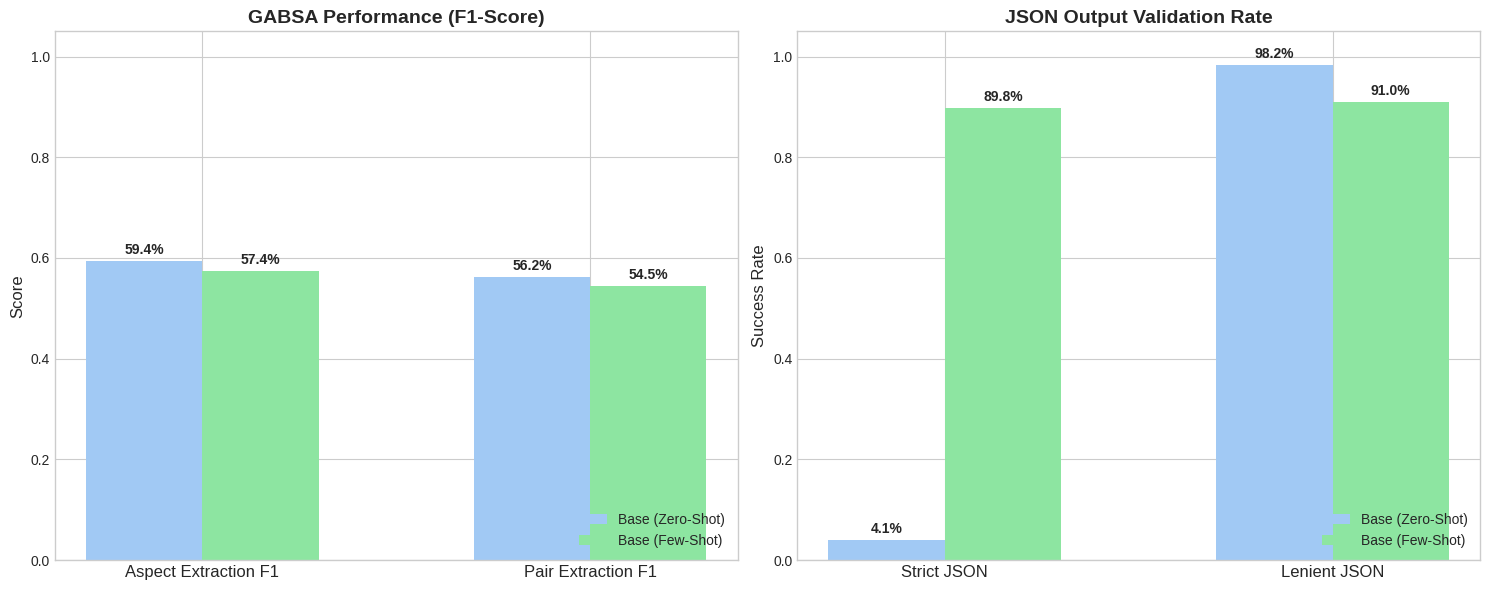

Grafik berhasil disimpan ke: /content/drive/MyDrive/Skripsi_v2/evaluation_results/baseline/baseline_gabsa_json_metrics.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. GABSA Extraction F1 Comparison
x_labels = ["Aspect Extraction F1", "Pair Extraction F1"]
base_zero_vals = [eval_gabsa_results["Base (Zero-Shot)"]["aspect_f1"], eval_gabsa_results["Base (Zero-Shot)"]["pair_f1"]]
base_few_vals = [eval_gabsa_results["Base (Few-Shot)"]["aspect_f1"], eval_gabsa_results["Base (Few-Shot)"]["pair_f1"]]

x = np.arange(len(x_labels))
width = 0.3

axes[0].bar(x - width/2, base_zero_vals, width, label='Base (Zero-Shot)', color='#a1c9f4')
axes[0].bar(x + width/2, base_few_vals, width, label='Base (Few-Shot)', color='#8de5a1')

axes[0].set_title('GABSA Performance (F1-Score)', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(x_labels, fontsize=12)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc='lower right')

# Tambahkan anotasi angka
for idx in range(len(x_labels)):
    axes[0].annotate(f'{base_zero_vals[idx]:.1%}', xy=(x[idx] - width/2, base_zero_vals[idx]),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[0].annotate(f'{base_few_vals[idx]:.1%}', xy=(x[idx] + width/2, base_few_vals[idx]),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. JSON Validation Rates Comparison
x_labels_json = ["Strict JSON", "Lenient JSON"]
base_zero_json = [eval_gabsa_results["Base (Zero-Shot)"]["strict_json_rate"], eval_gabsa_results["Base (Zero-Shot)"]["lenient_json_rate"]]
base_few_json = [eval_gabsa_results["Base (Few-Shot)"]["strict_json_rate"], eval_gabsa_results["Base (Few-Shot)"]["lenient_json_rate"]]

axes[1].bar(x - width/2, base_zero_json, width, label='Base (Zero-Shot)', color='#a1c9f4')
axes[1].bar(x + width/2, base_few_json, width, label='Base (Few-Shot)', color='#8de5a1')

axes[1].set_title('JSON Output Validation Rate', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(x_labels_json, fontsize=12)
axes[1].set_ylabel('Success Rate', fontsize=12)
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc='lower right')

# Tambahkan anotasi angka
for idx in range(len(x_labels_json)):
    axes[1].annotate(f'{base_zero_json[idx]:.1%}', xy=(x[idx] - width/2, base_zero_json[idx]),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')
    axes[1].annotate(f'{base_few_json[idx]:.1%}', xy=(x[idx] + width/2, base_few_json[idx]),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, "baseline_gabsa_json_metrics.png")
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"Grafik berhasil disimpan ke: {plot_path}")


## 12. Save Predictions to Excel/CSV
Menyimpan output prediksi mentah beserta ground truth-nya ke file excel untuk mempermudah analisis kualitatif pasca-inferensi.


In [ ]:
save_pred_dir = os.path.join(OUTPUT_DIR, "predictions_tables")
os.makedirs(save_pred_dir, exist_ok=True)

# Simpan Prediksi Task A
pd.DataFrame(gabsa_base_zero)[['text_clean', 'labels', 'prediction_raw', 'inference_time_sec']].to_excel(
    os.path.join(save_pred_dir, "gabsa_zero_shot_predictions.xlsx"), index=False
)
pd.DataFrame(gabsa_base_few)[['text_clean', 'labels', 'prediction_raw', 'inference_time_sec']].to_excel(
    os.path.join(save_pred_dir, "gabsa_few_shot_predictions.xlsx"), index=False
)

# Simpan Prediksi Task B
pd.DataFrame(summary_base_zero)[['input_stats', 'target_summary', 'prediction_raw', 'inference_time_sec']].to_excel(
    os.path.join(save_pred_dir, "summary_zero_shot_predictions.xlsx"), index=False
)
pd.DataFrame(summary_base_few)[['input_stats', 'target_summary', 'prediction_raw', 'inference_time_sec']].to_excel(
    os.path.join(save_pred_dir, "summary_few_shot_predictions.xlsx"), index=False
)

print(f"Semua prediksi mentah berhasil diekspor ke folder: {save_pred_dir}")


Semua prediksi mentah berhasil diekspor ke folder: /content/drive/MyDrive/Skripsi_v2/evaluation_results/baseline/predictions_tables


## 13. Qualitative Generation Check
Pengecekan hasil keluaran model secara kualitatif pada baris pertama masing-masing dataset test.


In [ ]:
print("=== CONTOH INFERENSI KUALITATIF - TASK A (GABSA) ===")
print(f"Teks Ulasan Asli:\n'{gabsa_test_data[0]['text_clean']}'\n")
print(f"Ground Truth:\n{json.dumps(gabsa_test_data[0]['labels'], indent=2)}\n")
print(f"Prediksi Base Model (Zero-Shot):\n{gabsa_base_zero[0]['prediction_raw']}\n")
print(f"Prediksi Base Model (Few-Shot):\n{gabsa_base_few[0]['prediction_raw']}\n")
print("="*80 + "\n")

print("=== CONTOH INFERENSI KUALITATIF - TASK B (SUMMARIZATION) ===")
print(f"Statistik Ulasan (Input):\n{summary_test_data[0]['input_stats']}\n")
print(f"Acuan Ringkasan Manusia (Ground Truth):\n{summary_test_data[0]['target_summary']}\n")
print(f"Generasi Base Model (Zero-Shot):\n{summary_base_zero[0]['prediction_raw']}\n")
print(f"Generasi Base Model (Few-Shot):\n{summary_base_few[0]['prediction_raw']}\n")


=== CONTOH INFERENSI KUALITATIF - TASK A (GABSA) ===
Teks Ulasan Asli:
'saya periksa tht dirumah sakit ini, mahal sekali tapi tidak dengan fasilitasnya. tidak ada pemeriksaan yang dijelaskan secara detail pada layar monitor, dokter pun juga tidak menjelaskan secara detail kondisi pasien, hanya diam dan bicara seperlunya. intinya tidak seperti klinik tht lainnya, tidak diperlihatkan kondisi kuping kita pada layar monitor. hanya dikasih obat tetes kuping lalu disuruh tunggu di depan buat tebus obat. sangat tidak memuaskan sekali. tolong diperbaiki pelayannya.'

Ground Truth:
[
  {
    "aspect": "tenaga_medis",
    "sentiment": "negatif",
    "evidence": "tidak ada pemeriksaan yang dijelaskan secara detail pada layar monitor, dokter pun juga tidak menjelaskan secara detail kondisi pasien, hanya diam dan bicara seperlunya"
  },
  {
    "aspect": "administrasi",
    "sentiment": "negatif",
    "evidence": "tidak diperlihatkan kondisi kuping kita pada layar monitor. hanya dikasih obat tetes 

```markdown
## 14. Multi-Label Confusion Matrix Visualization
Bagian ini menampilkan confusion matrix untuk setiap aspek pada Task A (GABSA) menggunakan hasil prediksi dari skenario **Few-Shot** (atau Anda bisa mengubahnya ke Zero-Shot).
```

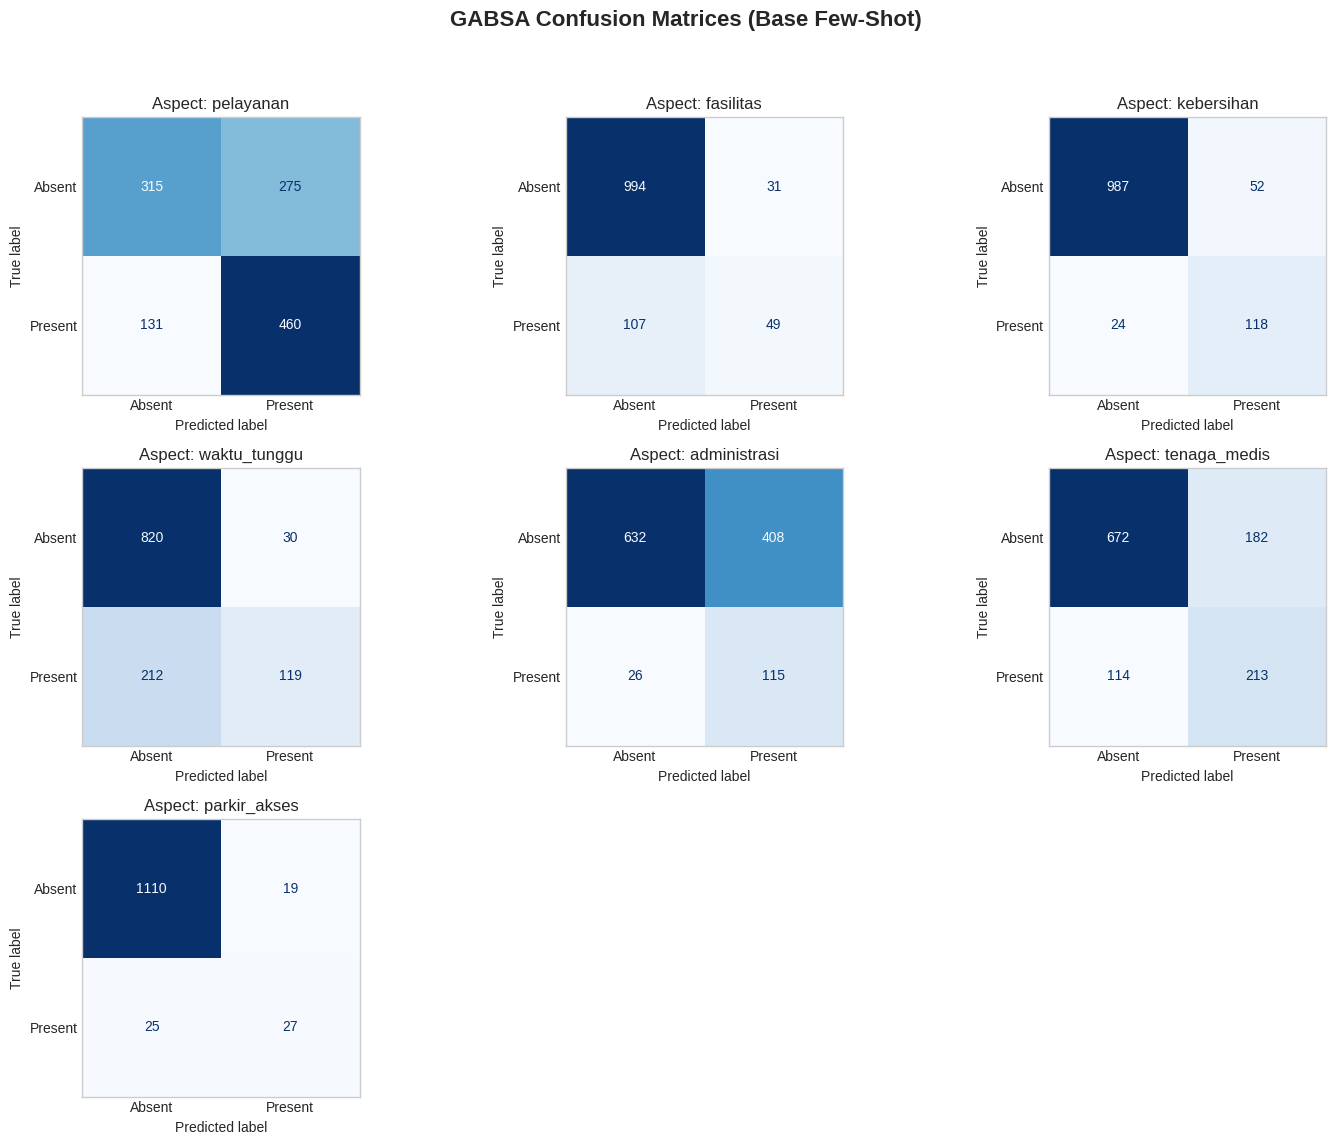

Confusion matrices disimpan ke: /content/drive/MyDrive/Skripsi_v2/evaluation_results/baseline/baseline_confusion_matrices.png


In [ ]:
from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay

def plot_multilabel_confusion_matrix(test_records, parsed_predictions, title="Confusion Matrix per Aspect"):
    aspect_list = ["pelayanan", "fasilitas", "kebersihan", "waktu_tunggu", "administrasi", "tenaga_medis", "parkir_akses"]

    y_true = []
    y_pred = []

    for gt_item, pred_labels in zip(test_records, parsed_predictions):
        gt_aspects = {l["aspect"].strip().lower() for l in gt_item["labels"] if "aspect" in l}
        pred_aspects = {l["aspect"].strip().lower() for l in pred_labels if "aspect" in l}

        y_true.append([1 if a in gt_aspects else 0 for a in aspect_list])
        y_pred.append([1 if a in pred_aspects else 0 for a in aspect_list])

    mcm = multilabel_confusion_matrix(y_true, y_pred)

    # Setup plot grid
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    axes = axes.ravel()

    for i, (matrix, aspect_name) in enumerate(zip(mcm, aspect_list)):
        disp = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=['Absent', 'Present'])
        disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
        axes[i].set_title(f'Aspect: {aspect_name}')
        axes[i].grid(False)

    # Hapus axis kosong
    for j in range(len(aspect_list), len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(title, fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    # Simpan plot
    cm_path = os.path.join(OUTPUT_DIR, "baseline_confusion_matrices.png")
    plt.savefig(cm_path, dpi=300)
    plt.show()
    print(f"Confusion matrices disimpan ke: {cm_path}")

# Menyiapkan label hasil parsing untuk Few-Shot
few_shot_parsed = []
for item in gabsa_base_few:
    lbls, _, _ = safe_parse_json(item["prediction_raw"])
    few_shot_parsed.append(lbls)

# Jalankan plot
plot_multilabel_confusion_matrix(gabsa_test_data, few_shot_parsed, title="GABSA Confusion Matrices (Base Few-Shot)")

```markdown
## 15. Zero-Shot Confusion Matrix Visualization
Bagian ini menampilkan confusion matrix untuk setiap aspek pada Task A (GABSA) menggunakan hasil prediksi dari skenario **Zero-Shot**.
```

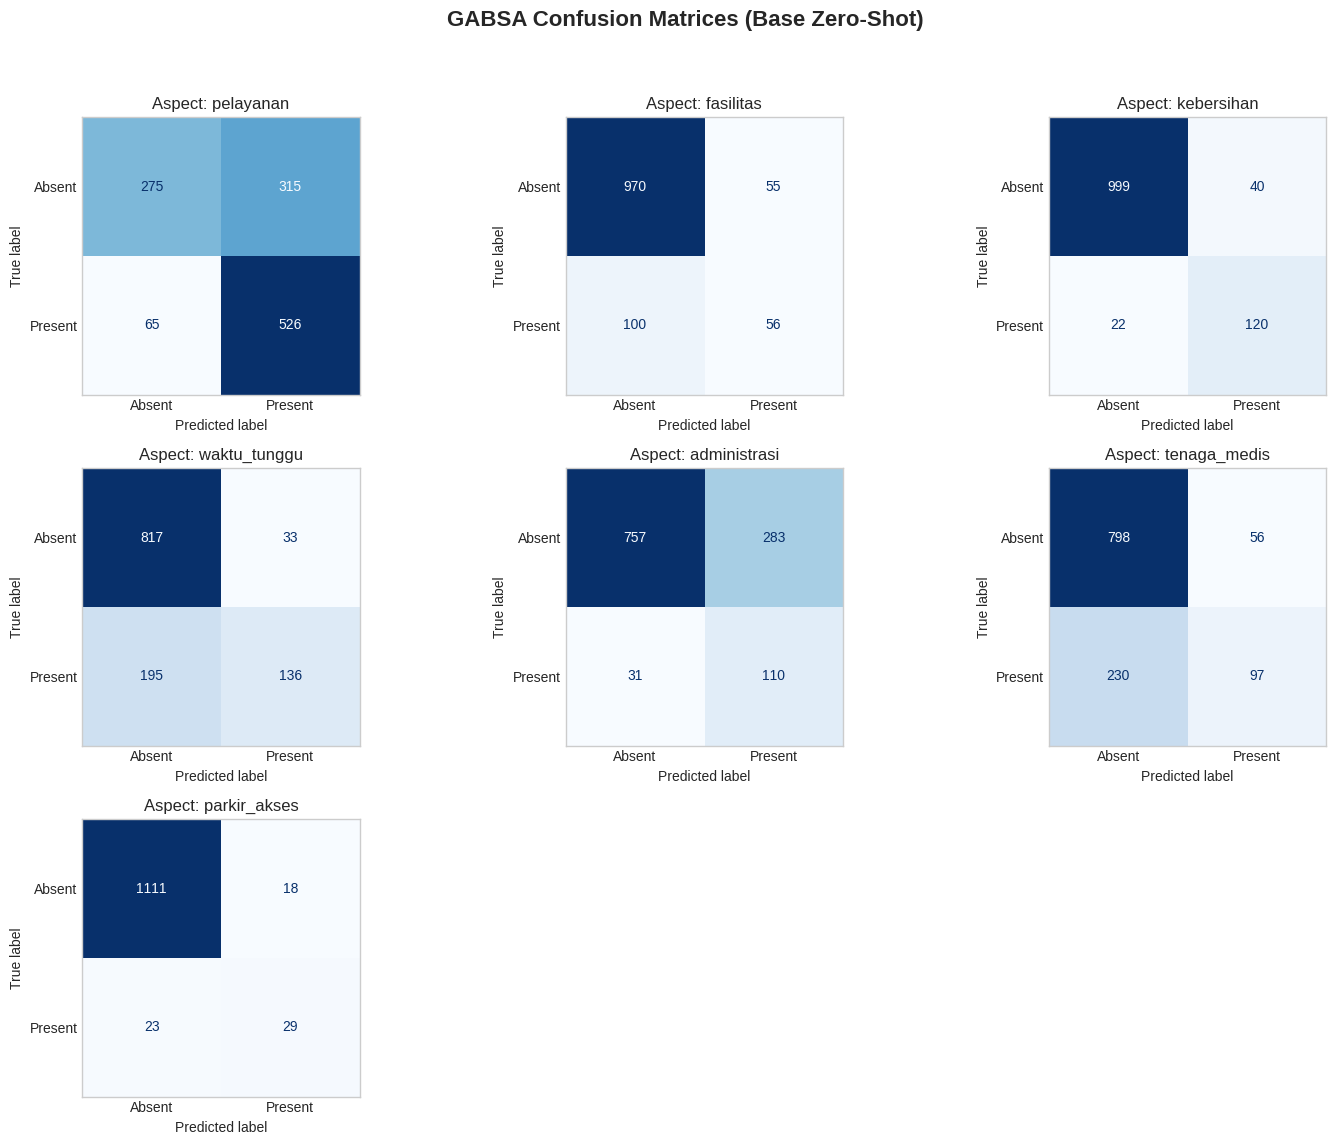

Confusion matrices disimpan ke: /content/drive/MyDrive/Skripsi_v2/evaluation_results/baseline/baseline_confusion_matrices.png


In [ ]:
# Menyiapkan label hasil parsing untuk Zero-Shot
zero_shot_parsed = []
for item in gabsa_base_zero:
    lbls, _, _ = safe_parse_json(item["prediction_raw"])
    zero_shot_parsed.append(lbls)

# Jalankan plot untuk Zero-Shot
plot_multilabel_confusion_matrix(
    gabsa_test_data,
    zero_shot_parsed,
    title="GABSA Confusion Matrices (Base Zero-Shot)"
)